In [22]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repo root: experiments/ -> Practical-Work-In-AI/

import src.cvem as cvem
import src.helpers as helpers
import src.step3_plots as step3_plots
import numpy as np
import json
from tqdm import tqdm
import math
import time
import pandas as pd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [23]:
# Define experiment constants
M = 252                 # number of discretization steps
T = 0.25                # maturity
r = 0.05                # risk-free rate
S_0 = 50                # initial price of the underlying
sigma = 0.3             # volatility

K = 50                  # strike

In [24]:
# Compute or load reference values
reference_file = Path("ref_values.json")
REF_KEYS = ("theta_ref", "theta_ref_SE", "b_hat_ref",
            "var_A_ref", "var_C_ref", "cov_AC_ref", "rho_AC_ref")

# parameters the reference values depend on; the cache is used only if they match
ref_params = {"M": M, "T": T, "r": r, "S_0": S_0, "sigma": sigma, "K": K}

# exact mean of the control (closed form, cheap, so not cached)
mu_C = cvem.discounted_geometric_asian_exact_mean(T, M, r, sigma, S_0, K)

def _compute_refs_and_save(reference_file, params, mu_C):
    N_ref = 10**7
    batch_size = 10**5

    # estimate b_hat_ref and the reference moments Var(A), Var(C), Cov(A, C)
    A = np.empty(N_ref)
    C = np.empty(N_ref)
    rng = np.random.default_rng(79)

    for k in tqdm(range(N_ref//batch_size), "Estimating b_hat_ref"):
        start = k * batch_size
        stop = start + batch_size
        log_paths = cvem.sample_GBM_log_paths(batch_size, T, M, r, sigma, S_0, rng)
        A[start:stop] = cvem.discounted_arithmetic_asian_payoff(log_paths, K, r, T)
        C[start:stop] = cvem.discounted_geometric_asian_payoff(log_paths, K, r, T)

    var_A_ref, var_C_ref, cov_AC_ref = cvem.compute_moments(A, C)
    rho_AC_ref = cov_AC_ref / math.sqrt(var_A_ref * var_C_ref)   # Corr(A, C)
    b_hat_ref = cov_AC_ref / var_C_ref                           # Cov(A, C) / Var(C)

    # estimate theta_ref
    # Since b_hat_ref is independent of the samples theta_ref 
    # is estimated on we can use control variate method
    # in order to reduce the variance of theta_ref.
    # We also note that such estimate is unbiased.
    rng = np.random.default_rng(43)

    for k in tqdm(range(N_ref//batch_size), "Estimating theta_ref"):
        start = k * batch_size
        stop = start + batch_size
        log_paths = cvem.sample_GBM_log_paths(batch_size, T, M, r, sigma, S_0, rng)
        A[start:stop] = cvem.discounted_arithmetic_asian_payoff(log_paths, K, r, T)
        C[start:stop] = cvem.discounted_geometric_asian_payoff(log_paths, K, r, T)
    theta_ref = cvem.cvem_estimate(A, C, b_hat_ref, mu_C)

    theta_ref_SE = np.std(A - b_hat_ref * (C - mu_C), ddof=1) / math.sqrt(N_ref)

    values = {
        "theta_ref": float(theta_ref),
        "theta_ref_SE": float(theta_ref_SE),
        "b_hat_ref": float(b_hat_ref),
        "var_A_ref": float(var_A_ref),
        "var_C_ref": float(var_C_ref),
        "cov_AC_ref": float(cov_AC_ref),
        "rho_AC_ref": float(rho_AC_ref),
    }
    reference_file.write_text(json.dumps({"params": params, "values": values}, indent=2))
    return values

def _load_refs(reference_file, params):
    """Return the stored values, or None if the file is missing, incomplete
    or was computed with different parameters."""
    if not reference_file.exists():
        return None
    stored = json.loads(reference_file.read_text())
    if stored.get("params") != params:
        print(f"{reference_file}: parameters differ from the stored ones, recomputing")
        return None
    values = stored.get("values", {})
    if all(key in values for key in REF_KEYS):
        return values
    return None

values = (_load_refs(reference_file, ref_params)
          or _compute_refs_and_save(reference_file, ref_params, mu_C))
theta_ref = values["theta_ref"]
theta_ref_SE = values["theta_ref_SE"]
b_hat_ref = values["b_hat_ref"]
var_A_ref = values["var_A_ref"]
var_C_ref = values["var_C_ref"]
cov_AC_ref = values["cov_AC_ref"]
rho_AC_ref = values["rho_AC_ref"]

print(f"theta_ref = {theta_ref} ± {theta_ref_SE}")
print(f"Var(A) = {var_A_ref}, Var(C) = {var_C_ref}, Cov(A, C) = {cov_AC_ref}, rho_AC = {rho_AC_ref}")

theta_ref = 1.8772110931177866 ± 1.7460287799375154e-05
Var(A) = 7.768778128570532, Var(C) = 7.395591239019697, Cov(A, C) = 7.578399946777781, rho_AC = 0.9998036372598933


In [25]:
# Measure or load the costs
costs_file = Path("costs.json")

def time_per_sample(f, n, repeats):
    """Smallest run time of f() over several repeats, divided by n."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        f()
        times.append(time.perf_counter() - start)
    return min(times) / n

def _measure_costs_and_save(costs_file):
    n_time = 20_000
    repeats = 50
    seed = 10
    rng = np.random.default_rng(seed)
    log_paths = cvem.sample_GBM_log_paths(n_time, T, M, r, sigma, S_0, rng)
    cost_A = time_per_sample(lambda: cvem.discounted_arithmetic_asian_payoff(cvem.sample_GBM_log_paths(n_time, T, M, r, sigma, S_0, rng), K, r, T), n_time, repeats)
    cost_C = time_per_sample(lambda: cvem.discounted_geometric_asian_payoff(log_paths, K, r, T), n_time, repeats)
    cost_C_prime = time_per_sample(lambda: cvem.sample_discounted_geometric_asian_aux(n_time, T, M, r, sigma, S_0, K, rng), n_time, repeats)

    costs = {"cost_A": cost_A, "cost_C": cost_C, "cost_C_prime": cost_C_prime,
             "c": cost_C / cost_A, "c_prime": cost_C_prime / cost_A}
    # save the costs together with the timing settings and the device they were measured on
    record = helpers.save_costs(
        costs_file, costs, repeats=repeats,
        params={"n_time": n_time, "M": M, "seed": seed, "statistic": "min"},
    )
    return record["costs"]

costs = helpers.load_costs(costs_file) or _measure_costs_and_save(costs_file)
c, c_prime = costs["c"], costs["c_prime"]
print(f"c = {c:.4f},  c' = {c_prime:.5f}")

c = 0.0156,  c' = 0.00233


In [38]:
B_values = [10**3, 3*10**3, 10**4]
kappa_values = np.logspace(-1, 4, 11) 
L = 500

def allocate_budget(B, kappa, c, c_prime) -> tuple[int, int]:
    N_k = int(math.floor(B / ((1 + c) + c_prime * kappa)))
    N_prime_k = max(2, int(math.floor(kappa * N_k)))
    return N_k, N_prime_k

def mse_stats(theta_hat):
    """Empirical MSE against theta_ref and its standard error."""
    sq_err = (theta_hat - theta_ref) ** 2
    return sq_err.mean(), sq_err.std(ddof=1) / np.sqrt(len(sq_err))

def compute_theoretical_stats(method, N, N_prime, B, MSE_emp, SE):
    if method == "MC":
        MSE_theory = var_A_ref/B
    elif method == "CV b_ref" or method == "CV b_hat":
        MSE_theory = var_A_ref * (1 - rho_AC_ref**2) / N
    elif method == "CVEM b_ref" or method == "CVEM b_hat":
        _kappa = N_prime / N
        MSE_theory = var_A_ref / N * (1-rho_AC_ref**2 * _kappa/(1+_kappa))
    else: 
        raise NameError("Method with that name does not exist")
    z = (MSE_emp - MSE_theory) / SE
    return MSE_theory, z

rng = np.random.default_rng(13)

# store results in form: budget, kappa, N, N_prime, method, MSE, SE
rows = []

if not Path("step3_results.csv").exists():
    for B in B_values:
        methods = ["MC", "CV b_ref", "CV b_hat"]
        estimates = {m: np.empty(L) for m in methods}

        N_CV = int(B // (1+c))
        for l in range(L):
            # 1. plain MC: all the budget B goes into samples of A
            log_paths = cvem.sample_GBM_log_paths(B, T, M, r, sigma, S_0, rng)
            A = cvem.discounted_arithmetic_asian_payoff(log_paths, K, r, T)
            estimates["MC"][l] = np.mean(A)

            # 2. CV with b estimated independently
            log_paths = cvem.sample_GBM_log_paths(N_CV, T, M, r, sigma, S_0, rng)
            A = cvem.discounted_arithmetic_asian_payoff(log_paths, K, r, T)
            C = cvem.discounted_geometric_asian_payoff(log_paths, K, r, T)
            estimates["CV b_ref"][l] = cvem.cvem_estimate(A, C, b_hat_ref, mu_C)

            # 3. CV with b estimated empirically
            _, var_C, cov_AC = cvem.compute_moments(A, C)
            b_hat_emp = cov_AC / var_C
            estimates["CV b_hat"][l] = cvem.cvem_estimate(A, C, b_hat_emp, mu_C)

        N_vals = [B, N_CV, N_CV]
        for i, (m, theta_hat) in enumerate(estimates.items()):
            mse, se = mse_stats(theta_hat)
            MSE_theory, z = compute_theoretical_stats(m, N_vals[i], 0, B, mse, se)
            rows.append({"B": B, "kappa": None, "N": N_vals[i], "N_prime": None,
                        "method": m, "MSE": mse, "SE": se, "MSE_theory": MSE_theory, "z-val": z, "c'N'/B": None})
            
        for kappa in kappa_values:
            N, N_prime = allocate_budget(B, kappa, c, c_prime)

            methods = ["CVEM b_ref", "CVEM b_hat"]
            estimates = {m: np.empty(L) for m in methods}

            for l in range(L):
                # prior
                prior_samples = cvem.sample_discounted_geometric_asian_aux(N_prime, T, M, r, sigma, S_0, K, rng)
                mu_C_hat = cvem.estimate_control_mean(prior_samples)

                # main
                log_paths = cvem.sample_GBM_log_paths(N, T, M, r, sigma, S_0, rng)
                A = cvem.discounted_arithmetic_asian_payoff(log_paths, K, r, T)
                C = cvem.discounted_geometric_asian_payoff(log_paths, K, r, T)

                var_A, var_C, cov_AC = cvem.compute_moments(A, C)

                # 4. CVEM with b estimated independently
                b_optimal_independent = cvem.compute_optimal_b(cov_AC_ref, var_C_ref, N, N_prime)
                estimates["CVEM b_ref"][l] = cvem.cvem_estimate(A, C, b_optimal_independent, mu_C_hat)

                # 5. CVEM with b estimated empirically
                b_optimal_empirical = cvem.compute_optimal_b(cov_AC, var_C, N, N_prime)
                estimates["CVEM b_hat"][l] = cvem.cvem_estimate(A, C, b_optimal_empirical, mu_C_hat)
            
            for m, theta_hat in estimates.items():
                mse, se = mse_stats(theta_hat)
                MSE_theory, z = compute_theoretical_stats(m, N, N_prime, B, mse, se)
                rows.append({"B": B, "kappa": kappa, "N": N, "N_prime": N_prime,
                    "method": m, "MSE": mse, "SE": se, "MSE_theory": MSE_theory, "z-val": z, "c'N'/B": c_prime*N_prime/B})

    results = pd.DataFrame(rows)
    results.to_csv("step3_results.csv", index=False)
else:
    results = pd.read_csv("step3_results.csv")
    results.to_csv("step3_results.csv", index=False)
results

,B,kappa,N,N_prime,method,MSE,SE,MSE_theory,z-val,c'N'/B
0,1000,NaN,1000,NaN,MC,0.007398,4.624473e-04,0.007769,-0.801503,0.000000
1,1000,NaN,984,NaN,CV b_ref,0.000003,1.962059e-07,0.000003,1.038652,0.000000
2,1000,NaN,984,NaN,CV b_hat,0.000003,1.972580e-07,0.000003,1.143371,0.000000
3,1000,0.10000,984,98.0,CVEM b_ref,0.006285,3.829132e-04,0.007180,-2.339234,0.000229
4,1000,0.10000,984,98.0,CVEM b_hat,0.006285,3.829162e-04,0.007180,-2.339108,0.000229
...,...,...,...,...,...,...,...,...,...,...
70,10000,1000.00000,2986,2986000.0,CVEM b_hat,0.000004,2.270147e-07,0.000004,-0.261880,0.696621
71,10000,3162.27766,1191,3766272.0,CVEM b_ref,0.000005,2.893110e-07,0.000005,0.298260,0.878655
72,10000,3162.27766,1191,3766272.0,CVEM b_hat,0.000005,2.954718e-07,0.000005,0.453814,0.878655
73,10000,10000.00000,410,4100000.0,CVEM b_ref,0.000009,5.309335e-07,0.000009,-0.679737,0.956513


Fix the budget $B$ and write $\kappa = N'/N$. Then $N = B / \big((1 + c) + c'\kappa\big)$. Using the MSE formula for $b^*(N')$ from the CVEM section,
$$
\mathrm{MSE}[\hat{A}_{\mathrm{CVEM}}(b^*(N'))] = \frac{\mathrm{Var}[A]}{N}\left(1 - \frac{\rho_{CA}^2\,\kappa}{1 + \kappa}\right).
$$
Plain MC with the same budget uses $B$ replications, so its MSE is $\mathrm{Var}[A]/B$. The ratio of the two is
$$
R(\kappa) = \frac{\mathrm{MSE}[\hat{A}_{\mathrm{CVEM}}(b^*(N'))]}{\mathrm{MSE}[\hat{A}_{\mathrm{MC}}]}\bigg|_{\text{same } B}
= \big((1 + c) + c'\kappa\big)\left(1 - \frac{\rho_{CA}^2\,\kappa}{1 + \kappa}\right).
$$
This ratio equals the ratio of the GMSEs and does not depend on $B$. For comparison, CV with known $\mu_C$ under the same budget gives $(1 + c)(1 - \rho_{CA}^2)$.
 
Setting $u = 1 + \kappa$ and differentiating,
$$
\frac{dR}{du} = c'\,(1 - \rho_{CA}^2) - \frac{(1 + c - c')\,\rho_{CA}^2}{u^2} = 0
\quad\Longrightarrow\quad
u^{*} = \left[\frac{\rho_{CA}^2}{1 - \rho_{CA}^2}\left(\frac{1 + c}{c'} - 1\right)\right]^{1/2} = \alpha .
$$
Hence $\kappa^{*} = \alpha - 1$

In [39]:
def optimal_kappa():
    alpha = ((rho_AC_ref**2 / (1 - rho_AC_ref**2)) * ((1+c)/c_prime - 1)) ** 0.5
    return alpha - 1

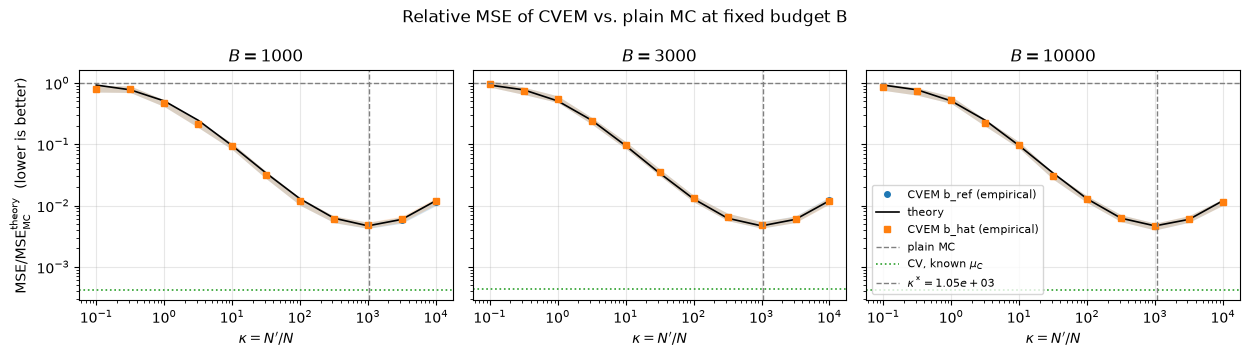

In [40]:
fig, axes = step3_plots.plot_mse_ratio_vs_kappa(results, kappa_star=optimal_kappa())
fig.savefig("../figures/step3_mse_ratio_vs_kappa.png")

Q1: "You mention that as the auxiliary sampling cost (c') tends to zero, almost the entire budget should be allocated to the auxiliary experiment. Could you verify this statement? In particular, what happens to the ratio (N'/N), and what happens to the fraction of the total computational budget spent on auxiliary samples? Are these necessarily the same?"

Q2: "You state that CVEM outperforms plain MC in terms of GMSE if and only if (\rho_{CA}^2 \geq c'/(1+c)). Could you revisit this condition and check whether it is sufficient when evaluating the control in the main experiment also has a cost (c>0)? I would like you to derive the comparison with plain MC explicitly."

Q3: "In the numerical experiment, you use an estimated coefficient (\hat b), whereas the theoretical MSE expressions are derived for an optimal coefficient. How exactly do you estimate (\hat b)? Does using the same sample introduce any bias or additional variability? Could this affect the comparison between theoretical and empirical MSE?"

Q4: "How did you obtain the values (c=0.016) and (c'=0.00232)? What operations are included in these measurements? Could you also check how sensitive your predicted optimal allocation is to changes in these values?"

Q5: "You report a more than 200-fold improvement over plain MC, which is interesting. However, the classical CV with known control mean still performs considerably better. What do you think is the main conclusion of this experiment? In which situations would CVEM be preferable or necessary?"